Proof of Concept

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("torch:", torch.__version__)
print("PyTorch MPS verfügbar:", torch.backends.mps.is_available())

Python: 3.11.15 (main, Mar 11 2026, 17:14:47) [Clang 20.1.8 ]
pandas: 3.0.3
numpy: 2.4.6
scikit-learn: 1.8.0
torch: 2.9.1
PyTorch MPS verfügbar: True


In [2]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
BENIGN_DIR = DATA_DIR / "benign"
MALICIOUS_DIR = DATA_DIR / "malicious"

RESULTS_DIR = BASE_DIR / "results"

csv_files = [
    "binary_information.csv",
    "commands.csv",
    "login_attempts.csv",
    "network_traffic.csv"
]

In [3]:
def load_dataset(file_name):
    benign_path = BENIGN_DIR / file_name
    malicious_path = MALICIOUS_DIR / file_name

    benign_df = pd.read_csv(benign_path)
    malicious_df = pd.read_csv(malicious_path)

    benign_df["label"] = 0
    malicious_df["label"] = 1

    combined_df = pd.concat([benign_df, malicious_df], ignore_index=True)

    return benign_df, malicious_df, combined_df


datasets = {}

for file_name in csv_files:
    dataset_name = file_name.replace(".csv", "")
    benign_df, malicious_df, combined_df = load_dataset(file_name)

    datasets[dataset_name] = {
        "benign": benign_df,
        "malicious": malicious_df,
        "combined": combined_df
    }

print(datasets)

{'binary_information': {'benign':                                              filename  count  \
0   c7b68ac37f364473e922936708e7f43c293dd07b295171...      1   
1   77af778b51abd4a3c51c5ddd97204a9c3ae614ebccb75a...      1   
2   faefbbbf05cb9cfb18112dde743b3eb327b5b26426f420...      1   
3   e6640de835ad09fb0a7367ee2e0ba99d0142c139db0272...      1   
4   0feef98ed807f72fe287f71ed82369c76d1d81825b8c01...      1   
5   37d2b12d5d9abc2a364ef9448767ee03938e383c028419...      1   
6   af9d2c92ddc38ca77b3cd29e944c9b61928032808d3a3c...      1   
7   5f53b0a2be22e28dc4b056f663910c046a33f9b2d779ea...      1   
8   427e4b79b1f0fc90306cbe064b1297b21dc6835bfa656d...      1   
9   570e342d0e4708dab94b2025f6b928845b659b405872d8...      1   
10  7f5a55cf3f88be936fb9440249cb449f3067ccee4b525d...      1   
11  a4a6172074384f943a78b96c7018ed9776cc3ab005ea58...      1   
12  24e5e1c2bbef565360c392851175f46821fc21d6725503...      1   
13  5009a047a11fbd680bb40d2f23cd3fcd626ac2d672c38e...      1   
14  7c

In [4]:
feature_configs = {
    "binary_information": {
        "target_col": "label",
        "drop_cols": ["label", "filename", "malware_name"],
        "numeric_cols": [
            "count",
            "obfuscation_Size(Bytes)",
            "obfuscation_Strings",
            "obfuscation_Strings_per_kB",
            "obfuscation_Entropy"
        ],
        "categorical_cols": [
            "file_type",
            "cpu_arch",
            "linkage",
            "anti_debugging"
        ],
        "multilabel_cols": [
            "c2_ports",
            "anti_forensic",
            "anti_sandbox",
            "persistence"
        ]
    },

    "commands": {
        "target_col": "label",
        "drop_cols": ["label"],
        "numeric_cols": ["count"],
        "categorical_cols": ["command"],
        "multilabel_cols": []
    },

    "login_attempts": {
        "target_col": "label",
        "drop_cols": ["label", "username:password"],
        "numeric_cols": ["count"],
        "categorical_cols": ["protocol", "successful"],
        "multilabel_cols": []
    },

    "network_traffic": {
        "target_col": "label",
        "drop_cols": ["label", "threat", "tags"],
        "numeric_cols": ["count"],
        "categorical_cols": ["src_ip", "url"],
        "multilabel_cols": []
    }
}


In [5]:
def clean_numeric_columns(df, numeric_cols):
    df = df.copy()

    for col in numeric_cols:
        df[col] = (
            df[col]
            .astype("string")
            .str.replace(",", ".", regex=False)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df


def split_multilabel_cell(value):
    if pd.isna(value):
        return ["Unknown"]

    value = str(value).strip()

    if value == "" or value.lower() == "unknown":
        return ["Unknown"]

    return [item.strip() for item in value.split(",") if item.strip()]


def preprocess_for_autoencoder(dataset_name, test_size=0.2, random_state=RANDOM_STATE):

    config = feature_configs[dataset_name]

    benign_df = datasets[dataset_name]["benign"].copy()
    malicious_df = datasets[dataset_name]["malicious"].copy()

    numeric_cols = config["numeric_cols"]
    categorical_cols = config["categorical_cols"]
    multilabel_cols = config["multilabel_cols"]
    target_col = config["target_col"]

    feature_cols = numeric_cols + categorical_cols + multilabel_cols

    benign_df = benign_df[feature_cols + [target_col]].copy()
    malicious_df = malicious_df[feature_cols + [target_col]].copy()

    benign_df = clean_numeric_columns(benign_df, numeric_cols)
    malicious_df = clean_numeric_columns(malicious_df, numeric_cols)

    benign_train_df, benign_test_df = train_test_split(
        benign_df,
        test_size=test_size,
        random_state=random_state,
        shuffle=True
    )

    test_df = pd.concat([benign_test_df, malicious_df], ignore_index=True)
    y_test = test_df[target_col].to_numpy()

    numeric_imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train_num = numeric_imputer.fit_transform(benign_train_df[numeric_cols])
    X_test_num = numeric_imputer.transform(test_df[numeric_cols])

    X_train_num = scaler.fit_transform(X_train_num)
    X_test_num = scaler.transform(X_test_num)

    X_train_parts = [X_train_num]
    X_test_parts = [X_test_num]

    if len(categorical_cols) > 0:
        train_cat = benign_train_df[categorical_cols].copy()
        test_cat = test_df[categorical_cols].copy()

        train_cat = train_cat.fillna("Unknown").astype(str)
        test_cat = test_cat.fillna("Unknown").astype(str)

        onehot = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

        X_train_cat = onehot.fit_transform(train_cat)
        X_test_cat = onehot.transform(test_cat)

        X_train_parts.append(X_train_cat)
        X_test_parts.append(X_test_cat)
    else:
        onehot = None

    multilabel_binarizers = {}

    for col in multilabel_cols:
        mlb = MultiLabelBinarizer()

        train_lists = benign_train_df[col].apply(split_multilabel_cell)
        test_lists = test_df[col].apply(split_multilabel_cell)

        X_train_mlb = mlb.fit_transform(train_lists)

        known_classes = set(mlb.classes_)
        test_lists_filtered = test_lists.apply(
            lambda values: [v for v in values if v in known_classes]
        )

        X_test_mlb = mlb.transform(test_lists_filtered)

        multilabel_binarizers[col] = mlb

        X_train_parts.append(X_train_mlb)
        X_test_parts.append(X_test_mlb)

    X_train = np.hstack(X_train_parts).astype(np.float32)
    X_test = np.hstack(X_test_parts).astype(np.float32)

    return {
        "dataset_name": dataset_name,
        "X_train": X_train,
        "X_test": X_test,
        "y_test": y_test,
        "benign_train_df": benign_train_df,
        "benign_test_df": benign_test_df,
        "test_df": test_df,
        "numeric_imputer": numeric_imputer,
        "scaler": scaler,
        "onehot": onehot,
        "multilabel_binarizers": multilabel_binarizers,
        "feature_cols": feature_cols,
        "numeric_cols": numeric_cols,
        "categorical_cols": categorical_cols,
        "multilabel_cols": multilabel_cols
    }

In [6]:
preprocessed_data = {}

for dataset_name in feature_configs.keys():
    result = preprocess_for_autoencoder(dataset_name)
    preprocessed_data[dataset_name] = result

In [7]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)


class VanillaAutoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        hidden_dim = max(8, min(64, input_dim // 2))
        latent_dim = max(2, min(16, input_dim // 4))

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

device: mps


In [8]:
def train_autoencoder(X_train, epochs=20, batch_size=32, learning_rate=0.001):
    
    input_dim = X_train.shape[1]
    model = VanillaAutoencoder(input_dim).to(device)

    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)

    dataset = TensorDataset(X_train_tensor)
    loader = DataLoader(
        dataset,
        batch_size=min(batch_size, len(dataset)),
        shuffle=True
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    losses = []
    model.train()

    for epoch in range(epochs):
        epoch_losses = []

        for batch in loader:
            x_batch = batch[0].to(device)

            optimizer.zero_grad()
            reconstructed = model(x_batch)
            loss = criterion(reconstructed, x_batch)

            loss.backward()
            optimizer.step()

            epoch_losses.append(loss.item())

        losses.append(float(np.mean(epoch_losses)))

    return model, losses


def calculate_reconstruction_error(model, X):

    model.eval()
    X_tensor = torch.tensor(X, dtype=torch.float32).to(device)

    with torch.no_grad():
        reconstructed = model(X_tensor)
        errors = torch.mean((X_tensor - reconstructed) ** 2, dim=1)

    return errors.cpu().numpy()


def run_autoencoder_experiment(dataset_name, epochs=20, batch_size=32, learning_rate=0.001, threshold_percentile=95):

    X_train = preprocessed_data[dataset_name]["X_train"]
    X_test = preprocessed_data[dataset_name]["X_test"]
    y_test = preprocessed_data[dataset_name]["y_test"]

    model, losses = train_autoencoder(
        X_train,
        epochs=epochs,
        batch_size=batch_size,
        learning_rate=learning_rate
    )

    train_errors = calculate_reconstruction_error(model, X_train)
    test_errors = calculate_reconstruction_error(model, X_test)

    threshold = np.percentile(train_errors, threshold_percentile)
    y_pred = (test_errors > threshold).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    if len(np.unique(y_test)) == 2:
        roc_auc = roc_auc_score(y_test, test_errors)
    else:
        roc_auc = np.nan

    return {
        "dataset_name": dataset_name,
        "model": model,
        "losses": losses,
        "train_errors": train_errors,
        "test_errors": test_errors,
        "threshold": threshold,
        "y_test": y_test,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    }

In [9]:
experiment_settings = {
    "binary_information": {"epochs": 20, "batch_size": 16, "learning_rate": 0.001},
    "commands": {"epochs": 20, "batch_size": 32, "learning_rate": 0.001},
    "login_attempts": {"epochs": 20, "batch_size": 4, "learning_rate": 0.001},
    "network_traffic": {"epochs": 20, "batch_size": 64, "learning_rate": 0.001},
}

results = {}

for dataset_name, settings in experiment_settings.items():
    print(f"Trainiert: {dataset_name}")
    results[dataset_name] = run_autoencoder_experiment(
        dataset_name=dataset_name,
        epochs=settings["epochs"],
        batch_size=settings["batch_size"],
        learning_rate=settings["learning_rate"],
        threshold_percentile=95
    )
    print("done")

Trainiert: binary_information
done
Trainiert: commands
done
Trainiert: login_attempts
done
Trainiert: network_traffic
done


In [10]:
overview_rows = []

for dataset_name in experiment_settings.keys():
    result = results[dataset_name]
    cm = result["confusion_matrix"]
    tn, fp, fn, tp = cm.ravel()
    y_test = result["y_test"]

    overview_rows.append({
        "dataset": dataset_name,
        "benign_training": preprocessed_data[dataset_name]["X_train"].shape[0],
        "testdata_total": preprocessed_data[dataset_name]["X_test"].shape[0],
        "benign_test": int((y_test == 0).sum()),
        "malicious_test": int((y_test == 1).sum()),
        "features": preprocessed_data[dataset_name]["X_train"].shape[1],
        "threshold": result["threshold"],
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
        "precision": result["precision"],
        "recall": result["recall"],
        "F1": result["f1"],
        "ROC_AUC": result["roc_auc"],
        "train_errors": result["train_errors"].mean(),
        "test_errors": result["test_errors"].mean(),
    })

gesamtuebersicht = pd.DataFrame(overview_rows)

columns_to_round = [
    "threshold",
    "precision",
    "recall",
    "F1",
    "ROC_AUC",
    "train_errors",
    "test_errors"
]

gesamtuebersicht_gerundet = gesamtuebersicht.copy()
gesamtuebersicht_gerundet[columns_to_round] = gesamtuebersicht_gerundet[columns_to_round].round(4)

display(gesamtuebersicht_gerundet)

,dataset,benign_training,testdata_total,benign_test,malicious_test,features,threshold,true_negatives,false_positives,false_negatives,true_positives,precision,recall,F1,ROC_AUC,train_errors,test_errors
0,binary_information,23,26,6,20,20,1.1430,6,0,8,12,1.0,0.6000,0.7500,0.9250,0.5096,116.205902
1,commands,287,1271,72,1199,288,0.0035,72,0,1160,39,1.0,0.0325,0.0630,0.4346,0.0035,17.775999
2,login_attempts,6,266678,2,266676,5,0.8348,2,0,258525,8151,1.0,0.0306,0.0593,0.3945,0.4392,1.713900
3,network_traffic,5831,1800,1458,342,3005,0.0007,1400,58,342,0,0.0,0.0000,0.0000,0.3265,0.0004,0.000300


In [11]:
def plot_reconstruction_errors(result, log_scale=True, save=True):

    dataset_name = result["dataset_name"]
    test_errors = result["test_errors"]
    threshold = result["threshold"]
    y_test = result["y_test"]

    sample_indices = np.arange(len(test_errors))

    benign_mask = y_test == 0
    malicious_mask = y_test == 1

    plt.figure(figsize=(14, 6))

    plt.scatter(
        sample_indices[benign_mask],
        test_errors[benign_mask],
        label="gutartige Daten",
        alpha=0.8
    )

    plt.scatter(
        sample_indices[malicious_mask],
        test_errors[malicious_mask],
        label="bösartige Daten",
        alpha=0.8
    )

    plt.axhline(
        threshold,
        linestyle="--",
        label=f"Schwellenwert = {threshold:.4f}"
    )

    if log_scale:
        plt.yscale("log")
        plt.ylabel("Rekonstruktionsfehler, logarithmische Skala")
        scale_suffix = "log"
    else:
        plt.ylabel("Rekonstruktionsfehler")
        scale_suffix = "normal"

    plt.xlabel("Stichprobenindex")
    plt.title(f"{dataset_name} - Rekonstruktionsfehler mit Schwellenwert")
    plt.legend()
    plt.grid(True)

    if save:
        plot_path = RESULTS_DIR / f"{dataset_name}_rekonstruktionsfehler_schwellenwert_{scale_suffix}.svg"
        plt.savefig(plot_path, bbox_inches="tight")
        print("Diagramm gespeichert:", plot_path)

    plt.show()

Diagramm gespeichert: /Users/caro/Documents/autoencoder_poc_testbed/results/binary_information_rekonstruktionsfehler_schwellenwert_log.svg


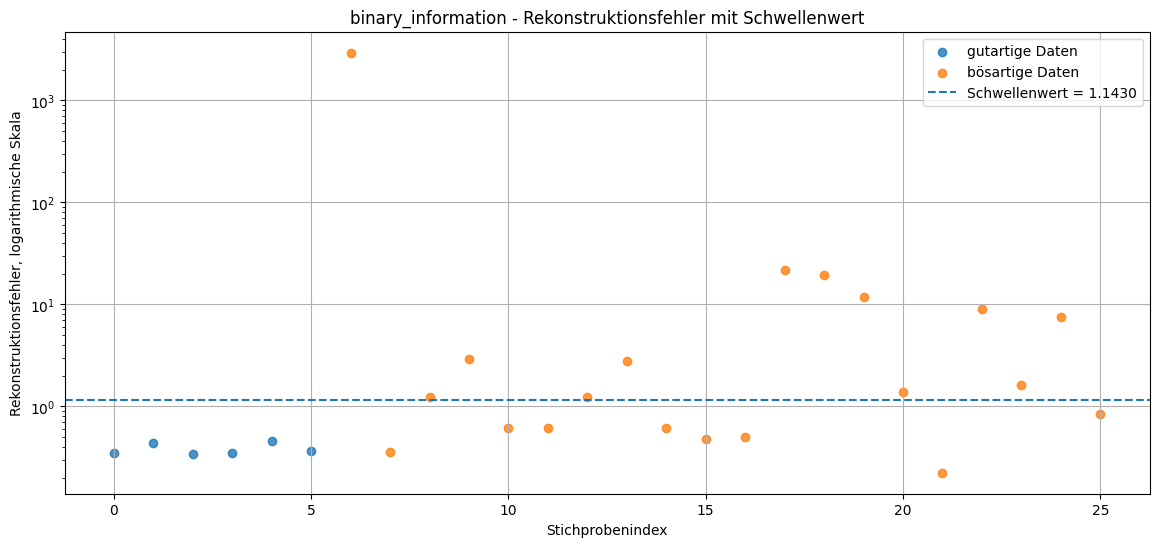

Diagramm gespeichert: /Users/caro/Documents/autoencoder_poc_testbed/results/commands_rekonstruktionsfehler_schwellenwert_log.svg


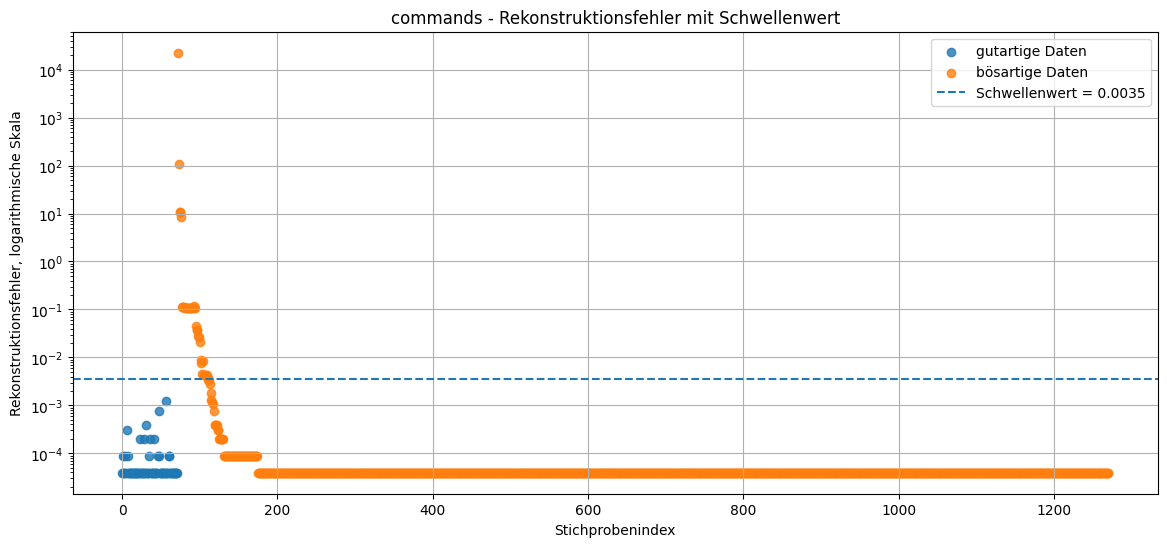

Diagramm gespeichert: /Users/caro/Documents/autoencoder_poc_testbed/results/login_attempts_rekonstruktionsfehler_schwellenwert_log.svg


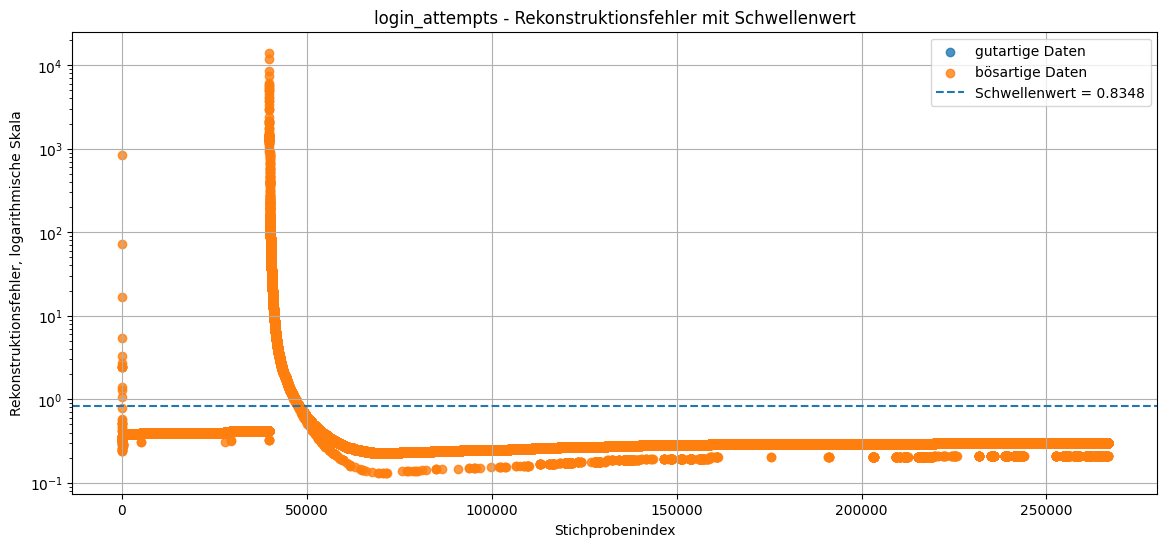

Diagramm gespeichert: /Users/caro/Documents/autoencoder_poc_testbed/results/network_traffic_rekonstruktionsfehler_schwellenwert_log.svg


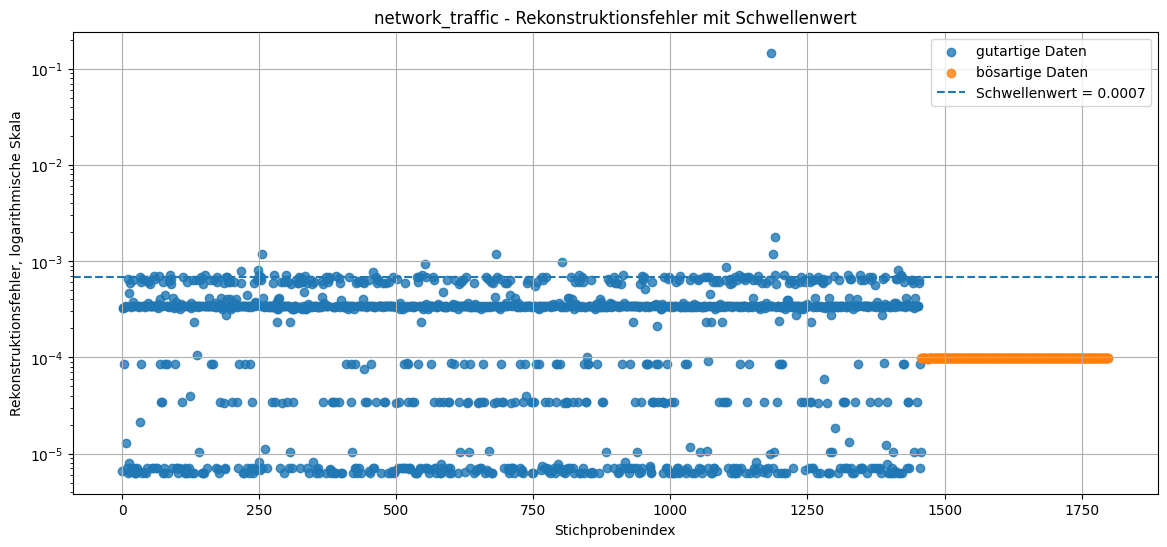

Gesamtübersicht gespeichert: /Users/caro/Documents/autoencoder_poc_testbed/results/gesamtuebersicht_autoencoder_poc.csv


In [12]:
for dataset_name, result in results.items():
    plot_reconstruction_errors(
        result,
        log_scale=True,
        save=True
    )

overview_path = RESULTS_DIR / "gesamtuebersicht_autoencoder_poc.csv"

gesamtuebersicht_gerundet.to_csv(
    overview_path,
    index=False,
    sep=";",
    decimal=","
)

print("Gesamtübersicht gespeichert:", overview_path)